<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [qslab](https://github.com/Gokaran-Shukla/qslab) · MIT License — any reuse must keep this copyright notice and credit the author.

# 05 · Triangular-lattice J₁-J₂ model: from 120° order to a spin liquid

**What you will learn**
1. ED scan in $J_2$: energy, the K-point order parameter, and the M point (stripe order).
2. DMRG on cylinders: convergence in $\chi$ and entanglement as a diagnostic.
3. The parton picture: Dirac spin liquid with π flux per unit cell.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED
from qslab.dmrg import DMRG
from qslab.parton import SpinonAnsatz, GutzwillerVMC

## 1. ED scan on the 12-site √12×√12 torus, parallel over J₂ with `pmap`
The tilted cluster $T_1 = 2a_1+2a_2,\ T_2=-2a_1+4a_2$ contains **both** the K point (120° order) and the M point (stripe order).
The rectangular 3×4 cluster does not contain K.

<Lattice triangular: N=12 sites, supercell=[[2, 2], [-2, 4]]> | contains K: True  M: True


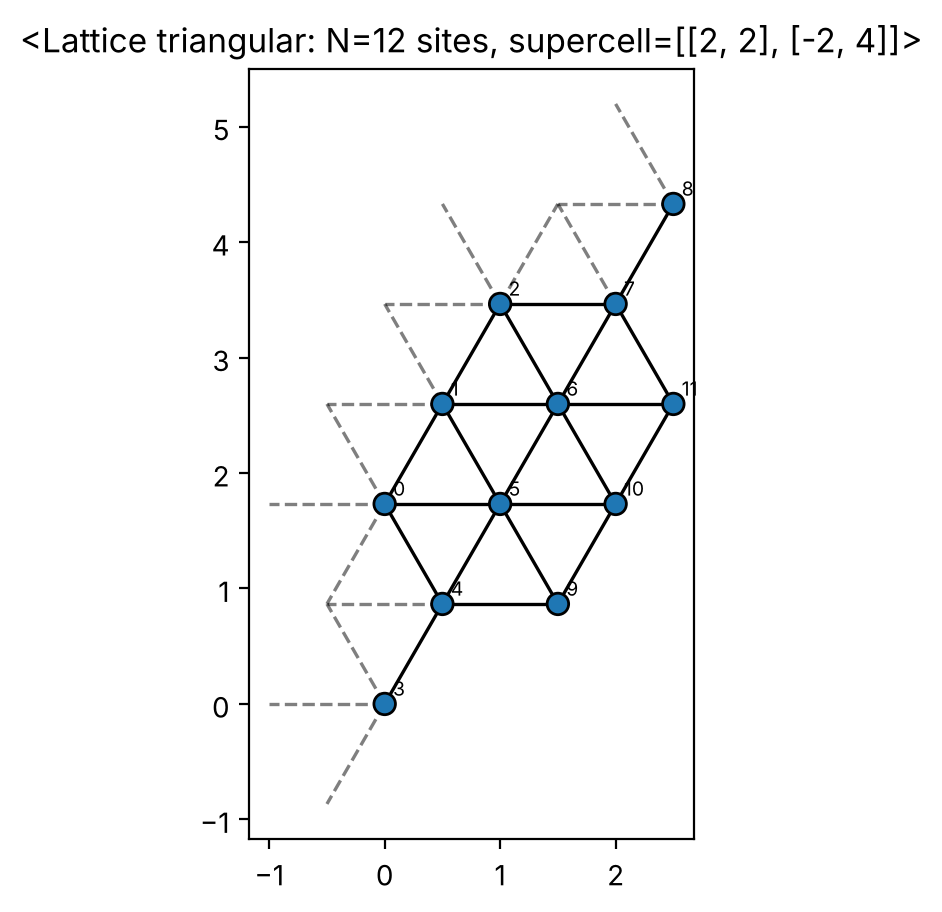

3.0s


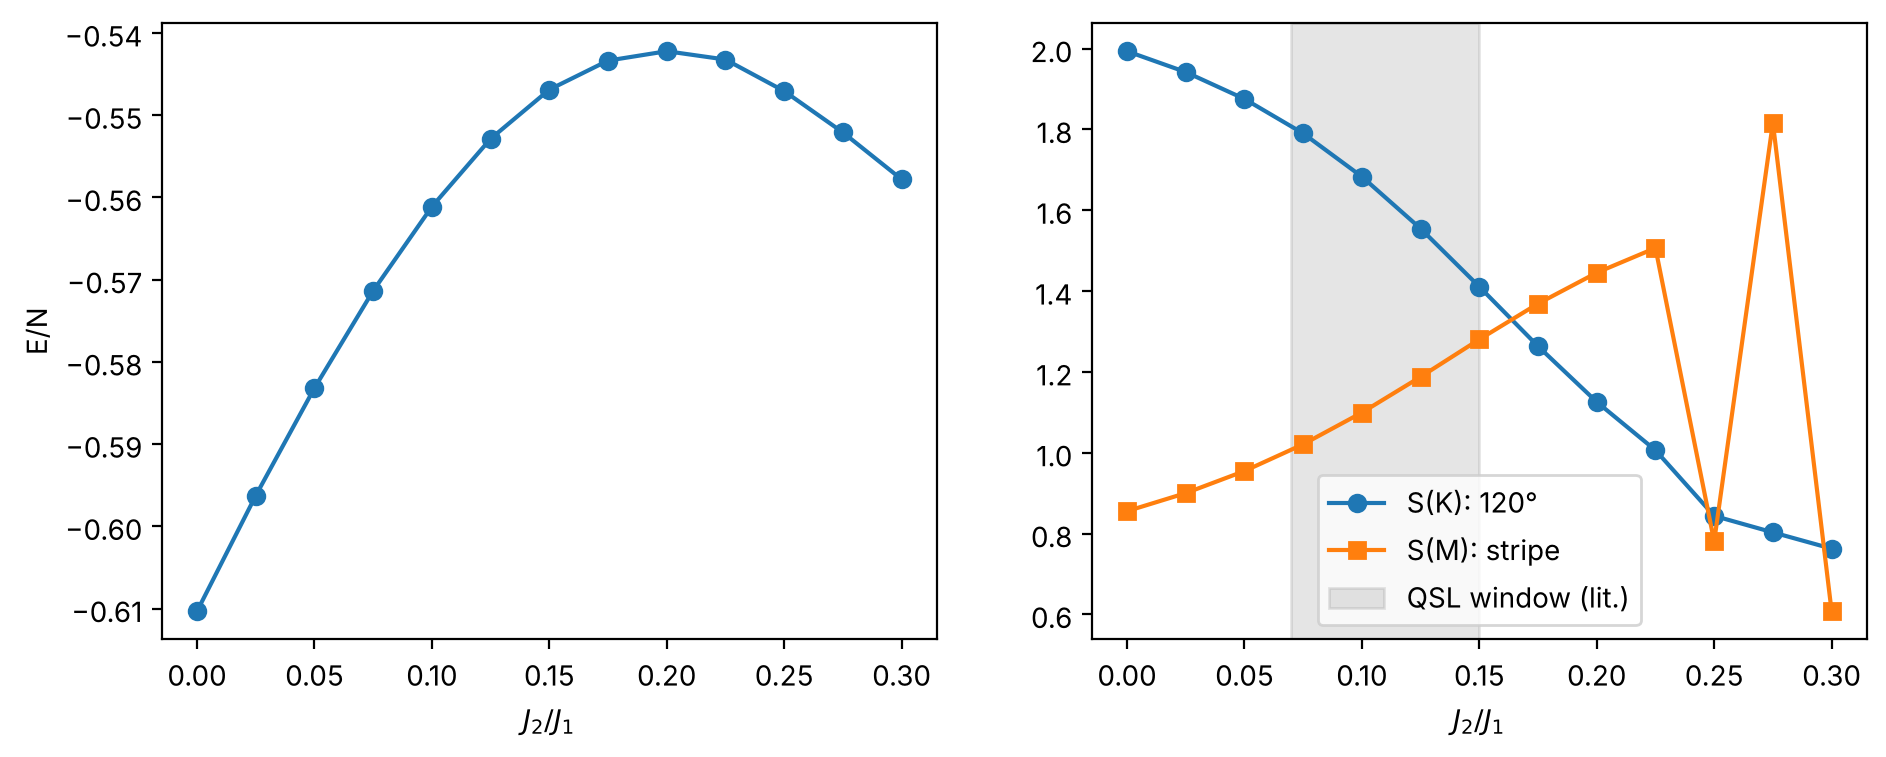

In [2]:
CLUSTER = [[2, 2], [-2, 4]]
lat = lattice.triangular(1, supercell=CLUSTER)
P = lat.high_symmetry_points()
B = lat.reciprocal()
def contains(k):
    return any(np.allclose(f - np.round(f), 0, atol=1e-6) for f in (np.linalg.solve(B.T, q - k) for q in lat.momenta()))
print(lat, "| contains K:", contains(P["K"]), " M:", contains(P["M"]))
lat.plot(); plt.show()

def scan(J2):
    lat = lattice.triangular(1, supercell=CLUSTER)
    ed = ED(models.j1j2_triangular(lat, J2=J2), lat.N)
    E, psi = ed.ground_state()
    C = ed.spin_correlations(psi)
    SK = ed.structure_factor(psi, lat.positions, P["K"], C=C)[0]
    SM = ed.structure_factor(psi, lat.positions, P["M"], C=C)[0]
    return E / lat.N, SK, SM

J2s = np.linspace(0, 0.3, 13)
t = time.time(); out = np.array(qslab.pmap(scan, J2s)); print(f"{time.time()-t:.1f}s")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(J2s, out[:, 0], "o-"); ax[0].set_ylabel("E/N")
ax[1].plot(J2s, out[:, 1], "o-", label="S(K): 120°"); ax[1].plot(J2s, out[:, 2], "s-", label="S(M): stripe")
ax[1].axvspan(0.07, 0.15, color="gray", alpha=0.2, label="QSL window (lit.)")
for a in ax: a.set_xlabel("$J_2/J_1$")
ax[1].legend(); plt.show()

## 2. DMRG on a cylinder
`bc='cylinder'` is open along $a_1$ and periodic along $a_2$, with column-by-column ordering. First compare with ED on a small cylinder, then watch the energy converge with the bond dimension χ.

In [3]:
lat = lattice.triangular(4, 3, bc="cylinder")
H = models.j1j2_triangular(lat, J2=0.1)
E_ed = ED(H, lat.N).ground_state()[0]
d = DMRG(H, lat.N, chi_max=128); d.run(8, verbose=False)
print("4x3 cylinder: DMRG", d.energy, " ED", E_ed)

4x3 cylinder: DMRG -5.95146985692296  ED -5.951469856922956


chi=  32: E/N=-0.524987  S_mid=0.358 (19s)


chi=  64: E/N=-0.525237  S_mid=0.379 (63s)


chi= 128: E/N=-0.525255  S_mid=0.383 (223s)


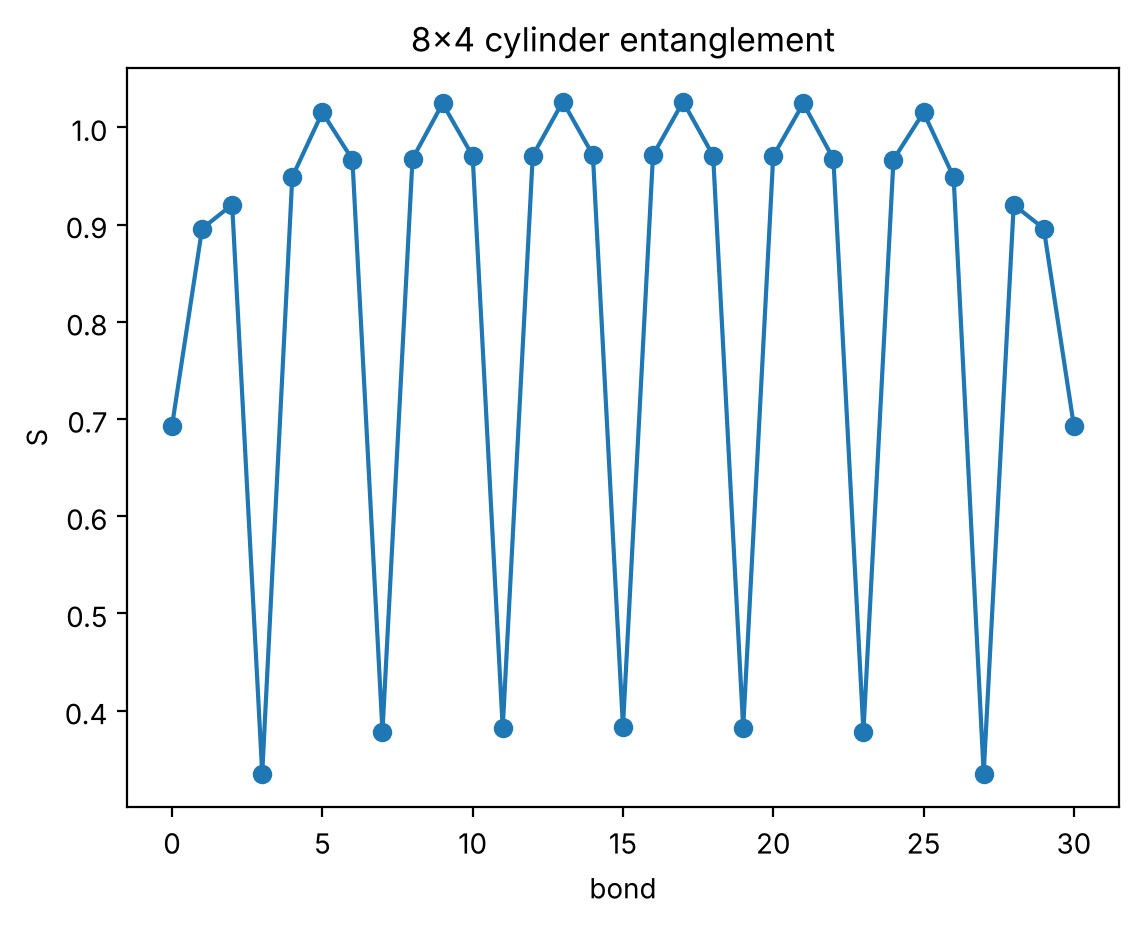

entanglement spectrum (lowest levels): [0.063 4.838 4.839 4.839 4.839 4.839 4.839 6.604]


In [4]:
lat = lattice.triangular(8, 4, bc="cylinder")
H = models.j1j2_triangular(lat, J2=0.1)
Es = []
for chi in [32, 64, 128]:
    d = DMRG(H, lat.N, chi_max=chi); t = time.time(); d.run(6, verbose=False)
    Es.append(d.energy / lat.N); print(f"chi={chi:4d}: E/N={d.energy/lat.N:.6f}  S_mid={d.entropies[lat.N//2-1]:.3f} ({time.time()-t:.0f}s)")
plt.plot(d.entropies, "o-"); plt.xlabel("bond"); plt.ylabel("S"); plt.title("8x4 cylinder entanglement"); plt.show()
print("entanglement spectrum (lowest levels):", np.round(d.entanglement_spectrum()[:8], 3))

## 3. Dirac spin liquid partons
π flux per unit cell: 0 through up triangles and π through down triangles.

In [5]:
lat = lattice.triangular(6, 6)
for name, fl in {"DSL (0 up, π down)": {"up": 0, "down": np.pi}, "uniform": {"up": 0, "down": 0}}.items():
    for tw in [(0, 0), (0, np.pi), (np.pi, 0), (np.pi, np.pi)]:
        ans = SpinonAnsatz.from_flux(lat, fl, twist=tw)
        if ans.fermi_gap() > 1e-6: break
    r = GutzwillerVMC(ans, J={1: 1.0, 2: 0.1}).run(n_sweeps=300, n_therm=50, n_chains=2)
    print(f"{name:20s}: E/N(J2=0.1) = {r['E_per_site']:.4f} ± {r['err_per_site']:.4f}")

DSL (0 up, π down)  : E/N(J2=0.1) = -0.5065 ± 0.0015


uniform             : E/N(J2=0.1) = -0.3497 ± 0.0043


## Quiz

In [6]:
from qslab import quiz
quiz.show("triangular")

=== Triangular J1-J2 Heisenberg model ===


Q1. [mcq] Ground state of the triangular J1 Heisenberg model?
    (a) 120-degree Neel order
    (b) ferromagnet
    (c) spin liquid
    (d) VBS

Q2. [mcq] Roughly where is the J2/J1 spin-liquid window?
    (a) none
    (b) 1 - 2
    (c) 0.5 - 0.6
    (d) 0.07 - 0.15

Q3. [numeric] ED energy per site on the 12-site (3x4) torus at J2 = 0?
    -> numeric answer (tolerance 2e-05)

Q4. [numeric] Same cluster at J2 = 0.1?
    -> numeric answer (tolerance 2e-05)

Q5. [mcq] Which momentum peaks in S(q) for 120-degree order?
    (a) none
    (b) M
    (c) Gamma
    (d) K (Brillouin-zone corner)

Q6. [mcq] Why do DMRG studies use YC/XC cylinders?
    (a) the MPS entanglement grows with circumference, and the orientation selects which momenta are allowed
    (b) they are faster than tori for no reason
    (c) SU(2) requires cylinders
    (d) to break time reversal

